In [30]:
# DataFlair Iris Flower Classification
# Import Packages
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

from sklearn.datasets import load_iris
import pandas as pd 

In [26]:
iris = load_iris()
X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['targets'] = y

df.head()

# The datasets contains 150 samples evenly sidtributed across three classes, with four continues numerical feature representing flower morphology.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),targets
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


<function matplotlib.pyplot.show(close=None, block=None)>

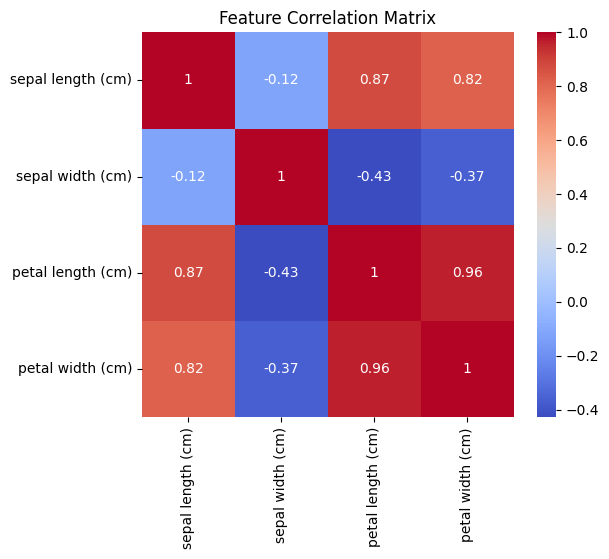

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
sns.heatmap(df[feature_names].corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show

# Petal features correlate strongly with class separation.

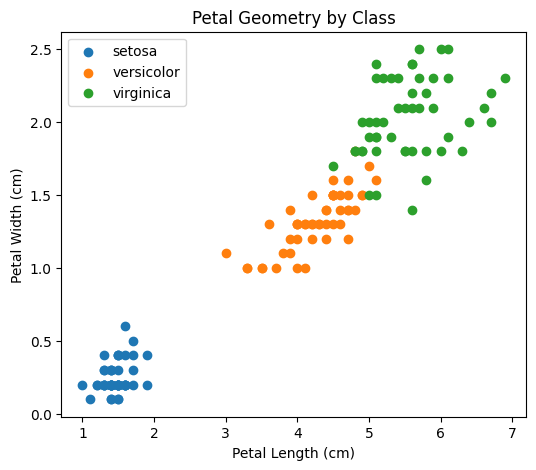

In [28]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target
target_names = iris.target_names


plt.figure(figsize=(6, 5))

for label in range(3):
    subset = df[df['target'] == label]
    plt.scatter(
        subset['petal length (cm)'],
        subset['petal width (cm)'],
        label=target_names[label]
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.title("Petal Geometry by Class")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# BaseLine Model

## Logistic Regression as Baseline
### - Linear model
### - Fast
### - Interpretable
### - Works well when classes are reasonably separable
### - Sets a clear performance floor




## 1: Training the Baseline model:

In [ ]:
# Training the Baseline model:

from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
baseline_model.fit(X_train_scaled, y_train)



## 2:___Make Predictions

In [ ]:
y_pred_baseline = baseline_model.predict(X_test_scaled)

## 3:___Baseline Evaluation Metrics

### Accuracy:

In [ ]:
from sklearn.metrics import accuracy_score

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_accuracy

### Classification:

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=target_names
))

## 4:__Confusion Matrix (Baseline)

In [ ]:
# Shows where the model is confused, not just how often.

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Baseline Logistic Regression – Confusion Matrix")
plt.show()


In [ ]:
# Key insight:

    #-Almost zero confusion for Setosa

    #-Small confusion zone between Versicolor & Virginica

# The IMPORTANT Note is : This tells us where advanced models must improve.

#### {The baseline logistic regression model performs strongly, with most misclassifications occurring between Versicolor and Virginica, indicating partial overlap in feature space.}

#### -----------------------------------------------------------------------------------------------------------------------------------------------------

#### -----------------------------------------------------------------------------------------------------------------------------------------------------

 # Model Enhancements:

## -System improve intelligently beyond the baseline.

### 1 — Common Evaluation Utility:

In [ ]:
#standardize evaluation so results are comparable.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    print(f"\n{name} Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=target_names))
    
    return acc, y_pred

# enforces discipline.

### 2 — KNN (Distance-Based Model).:

In [ ]:
# Training

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_acc, y_pred_knn = evaluate_model(
    knn_model, X_test_scaled, y_test, "KNN (k=5)"
)

# Observe:
    #--Performance similar or slightly better than baseline
    #--Still some confusion in Versicolor/Virginica

### 3 — SVM with RBF Kernel (Non-Linear Boundary)

In [ ]:
#Training

from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_acc, y_pred_svm = evaluate_model(
    svm_model, X_test_scaled, y_test, "SVM (RBF)"
)

#Expect:

    # ~ Near-perfect accuracy

    # ~ Minimal confusion

# This validates non-linear geometry.

### 4 — Random Forest (Ensemble Learning):


In [ ]:
#Training

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)  # RF does NOT need scaling

rf_acc, y_pred_rf = evaluate_model(
    rf_model, X_test, y_test, "Random Forest"
)


#Observe:

    #~Strong accuracy

    #~Different error pattern from SVM

### 5 — Model Comparison Summary (Critical):

In [ ]:
# Now we condense insight.

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression (Baseline)",
        "KNN (k=5)",
        "SVM (RBF)",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        knn_acc,
        svm_acc,
        rf_acc
    ]
})

results



## ------------------------------------------------------

## Interpretation:-

####  { Compared to the linear baseline, non-linear models such as SVM and Random Forest achieve improved performance by capturing curved decision boundaries in the feature space. SVM with RBF kernel provides the strongest balance between accuracy and stability for this dataset. }

### 6 — Confusion Matrix:

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM (RBF) – Confusion Matrix")
plt.show()


### -----------------------------------------------------------------------------------------

## Visualization of Model Behavior

### 1 — 3D PCA Line (Species Geometry)

In [ ]:
# Code: 3D PCA Mean Trajectory

from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.pyplot as plt

# PCA with 3 components
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_train_scaled)

# Compute class-wise mean points
mean_points = []
for label in np.unique(y_train):
    mean_points.append(X_pca_3[y_train == label].mean(axis=0))

mean_points = np.array(mean_points)

# Plot 3D line
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.plot(
    mean_points[:, 0],
    mean_points[:, 1],
    mean_points[:, 2],
    marker='o',
    linewidth=3,
    color='black'
)

# Label points
for i, label in enumerate(target_names):
    ax.text(
        mean_points[i, 0],
        mean_points[i, 1],
        mean_points[i, 2],
        label,
        color='red',
        size=10
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Line: Mean Species Geometry")

plt.show()


### { This plot shows how the mean position of each Iris species shifts across the first three principal components. }

## 2 — 3D Neural Network Decision Surface (Model Geometry)

#### --visualing how a Neural Network Thinks:

#### 2_Part-1 Prepare Data:

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

X_nn = df[['petal length (cm)', 'petal width (cm)']].values
y_nn = y

X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(
    X_nn, y_nn,
    test_size=0.2,
    stratify=y_nn,
    random_state=42
)


#### 2_Part-2 Train Neural Network:

In [ ]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    max_iter=2000,
    random_state=42
)

nn_model.fit(X_train_nn, y_train_nn)


#### 2_Part-3 Create 3D Probability Surface:

In [ ]:
- plot probability of Virginica (class index = 2).

In [ ]:
# Create grid
x_min, x_max = X_nn[:, 0].min() - 1, X_nn[:, 0].max() + 1
y_min, y_max = X_nn[:, 1].min() - 1, X_nn[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
probs = nn_model.predict_proba(grid)

Z = probs[:, 2].reshape(xx.shape)


#### 2_Part-3 Plot 3D Neural Surface:

In [ ]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(
    xx, yy, Z,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax.set_xlabel("Petal Length (cm)")
ax.set_ylabel("Petal Width (cm)")
ax.set_zlabel("NN Probability (Virginica)")
ax.set_title("Neural Network Decision Surface (3D)")

fig.colorbar(surface, ax=ax, shrink=0.5)
plt.show()


#### ( This surface represents how the neural network maps petal dimensions to class probability in a continuous decision space. )